# 1. Datos y preprocesamiento — 3DAeroRelief
Detección de daños estructurales en nubes de puntos de dron (Electiva de Ingeniería de Software, USB Cali).

Este notebook documenta el dataset y el preprocesamiento descritos en la sección *Metodología* del informe:
fusión de etiquetas, **alineación vertical**, **armonización de escala**, submuestreo por vóxel y normales.

> El dataset original (≈21 GB) se descarga de <https://github.com/BinaLab/3DAeroRelief> y se descomprime en `data/3DAeroRelief/`.

In [1]:
import json, sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent            # carpeta raíz del proyecto
sys.path.insert(0, str(ROOT / "code"))
DATA, RAW, RUNS = ROOT / "data" / "processed", ROOT / "data" / "3DAeroRelief", ROOT / "runs"
CLASES = ["Fondo", "Edif. dañada", "Edif. sin daño", "Vía", "Árbol"]
pd.set_option("display.precision", 3)
print("Proyecto:", ROOT.name)

Proyecto: Proyecto_Electiva_Danos_Estructurales


## 1.1 Comandos de preprocesamiento
El preprocesamiento completo tarda ~30 min, así que se ejecuta con los scripts de `code/`. Cambie `EJECUTAR` a `True` para repetirlo.

In [2]:
EJECUTAR = False
comandos = [
    "python preprocess.py --input ../data/3DAeroRelief --output ../data/processed --voxel 0.1",
    "python estimate_scale.py ../data/processed ../data/scale.json",
    "python preprocess.py --input ../data/3DAeroRelief --output ../data/processed --voxel 0.1 --scale ../data/scale.json --areas Area_4 Area_6",
    "python add_normals.py ../data/processed",
]
for c in comandos:
    print(c)
if EJECUTAR:
    import subprocess
    for c in comandos:
        subprocess.run([sys.executable] + c.split()[1:], cwd=ROOT / "code", check=True)

python preprocess.py --input ../data/3DAeroRelief --output ../data/processed --voxel 0.1
python estimate_scale.py ../data/processed ../data/scale.json
python preprocess.py --input ../data/3DAeroRelief --output ../data/processed --voxel 0.1 --scale ../data/scale.json --areas Area_4 Area_6
python add_normals.py ../data/processed


## 1.2 Estadísticas del dataset (Tabla de estadísticas del informe)

In [3]:
stats = json.loads((DATA / "stats.json").read_text())
df = pd.DataFrame(stats)
uso = {"Area_2": "Prueba", "Area_8": "Validación"}
filas = []
for area, g in df.groupby("area", sort=False):
    c = np.sum(np.stack(g["counts"].values), 0)
    filas.append(dict(Área=area, Uso=uso.get(area, "Entrenamiento"), Nubes=len(g),
                      **{"Puntos orig. (M)": g["n_raw"].sum() / 1e6, "Tras vóxel (M)": g["n"].sum() / 1e6},
                      **{f"{k} %": 100 * v / c.sum() for k, v in zip(CLASES, c)}))
tabla = pd.DataFrame(filas).sort_values("Área", key=lambda s: s.str[5:].astype(int))
tot = np.sum(np.stack(df["counts"].values), 0)
tabla.loc[len(tabla)] = dict(Área="Total", Uso="—", Nubes=len(df), **{"Puntos orig. (M)": df["n_raw"].sum() / 1e6,
                             "Tras vóxel (M)": df["n"].sum() / 1e6}, **{f"{k} %": 100 * v / tot.sum() for k, v in zip(CLASES, tot)})
tabla.round(1)

,Área,Uso,Nubes,Puntos orig. (M),Tras vóxel (M),Fondo %,Edif. dañada %,Edif. sin daño %,Vía %,Árbol %
0,Area_1,Entrenamiento,7,5.7,2.5,25.6,17.8,33.6,13.8,9.2
1,Area_2,Prueba,8,30.9,1.7,28.2,37.8,20.8,0.6,12.7
2,Area_3,Entrenamiento,13,90.4,2.9,33.6,35.7,16.3,2.2,12.2
3,Area_4,Entrenamiento,4,7.8,2.4,59.0,20.9,2.8,1.5,15.8
4,Area_5,Entrenamiento,4,28.4,1.3,45.8,31.8,0.0,11.7,10.6
5,Area_6,Entrenamiento,12,15.3,5.4,42.0,10.3,12.8,5.7,29.2
6,Area_7,Entrenamiento,10,5.2,1.6,33.4,31.0,21.0,6.0,8.6
7,Area_8,Validación,6,4.8,0.9,22.2,9.5,30.8,18.5,19.0
8,Total,—,64,188.5,18.8,37.9,22.2,16.3,6.4,17.1


## 1.3 Alineación vertical (verificación con etiquetas)
La vertical se fija sin etiquetas (PCA + normales). Aquí se **verifica a posteriori** que edificación y árbol queden por encima de vía y fondo.

In [4]:
ok = []
for s in stats:
    z = s["z_mean_per_class"]
    alto = [z[k] for k in (1, 2, 4) if z[k] is not None]
    bajo = [z[k] for k in (0, 3) if z[k] is not None]
    ok.append(np.mean(alto) > np.mean(bajo))
print(f"Nubes con orientación consistente: {sum(ok)} de {len(ok)}")
print("Excepciones:", [f"{s['area']}/{s['cloud']}" for s, o in zip(stats, ok) if not o])

Nubes con orientación consistente: 62 de 64
Excepciones: ['Area_1/pp7', 'Area_3/pp11']


## 1.4 Armonización de escala
Factores estimados solo con áreas de entrenamiento/validación (el Área 2 de prueba no se usa).

In [5]:
escala = json.loads((ROOT / "data" / "scale.json").read_text())
pd.DataFrame({"altura típica edificación (m)": escala["height"], "factor aplicado": escala["scale"]})

,altura típica edificación (m),factor aplicado
Area_1,3.094,1.000
Area_3,1.981,1.000
Area_4,8.623,0.285
Area_5,1.875,1.000
Area_6,6.946,0.354
Area_7,2.470,1.000
Area_8,2.445,1.000


## 1.5 Distribución de clases por área y normales

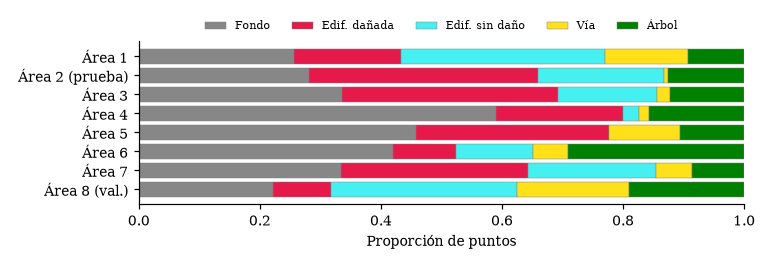

Campos de cada nube procesada: ['xyz', 'rgb', 'label', 'normal'] | puntos: 242403 | componente vertical media de la normal: 0.577


In [6]:
from make_figures import distribution
distribution(str(DATA), ROOT / "entrega_final" / "figs")
from IPython.display import Image, display
display(Image(filename=str(ROOT / "entrega_final" / "figs" / "distribucion.png")))
d = np.load(DATA / "Area_2_pp6.npz")
print("Campos de cada nube procesada:", list(d.keys()), "| puntos:", len(d["xyz"]),
      "| componente vertical media de la normal:", round(float(d["normal"][:, 2].mean()), 3))